#### NLP Task

Sentiment Analysis – IMDB Movie Reviews

## Objective
Objective of this project is to perform a comparative analysis of different transformer-based models on a selected NLP task. The models are evaluated based on performance metrics such as accuracy and F1-score, along with efficiency measures including training and inference time. This analysis helps identify the most suitable transformer model for real-world NLP applications based on performance and resource utilization.

### Step 1:Environment Setup-
To ensure all project members work in a consistent and error-free setup, a dedicated Conda environment was created for this project.

Steps to Create and Use Conda Environment
1️⃣ Install Prerequisites
Ensure Python 3.10 is available

2️⃣ Open Anaconda Prompt

Launch Anaconda Prompt (not CMD or PowerShell)

3️⃣ Create a New Conda Environment

Create a Conda environment named nlp_env:

conda create -n nlp_env python=3.10 -y

4️⃣ Activate the Environment

Activate the newly created environment:

conda activate nlp_env
Upgrade pip inside the environment:

python -m pip install --upgrade pip

6️⃣ Install Required Libraries (Fixed Versions)

Install stable and compatible library versions:

pip install pandas==1.5.3 numpy==1.24.4 matplotlib==3.7.3 seaborn==0.12.2 nltk==3.8.1

pip install torch==2.1.2 transformers==4.36.2 scikit-learn==1.3.2 accelerate==0.25.0 datasets==2.16.1

7️⃣ Install Jupyter Kernel Support

Install ipykernel inside the Conda environment:

pip install ipykernel

8️⃣ Register Conda Environment as Jupyter Kernel

Register the environment so it appears in Jupyter:

python -m ipykernel install --user --name nlp_env --display-name "Python (nlp_env)"

9️⃣ Launch Jupyter Notebook

Start Jupyter Notebook:

jupyter notebook

🔟 Select the Correct Kernel in Jupyter

In the notebook menu:

Kernel → Change Kernel → Python (nlp_env)

1️⃣1️⃣ Verify Active Environment

Run the following code in a notebook cell:

import sys
print(sys.executable)


Expected output:

...\nlp_env\python.exe

### Step 2:Import Libraries

In [1]:
import pandas as pd  #Data manipulation and analysis.
import matplotlib.pyplot as plt  #  Foundational data visualization.
import seaborn as sns    #Statistical data visualization.
import nltk    # Natural Language Processing (NLP)

from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split


In [2]:
nltk.download('punkt')  #pre-trained tokenizer model used by NLTK

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

### STEP 3: Load Dataset

In [3]:
df = pd.read_csv("IMDB Dataset.csv", engine="python", on_bad_lines="skip")
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


### STEP 4: Basic Dataset Check

In [4]:
df.shape

(20559, 2)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20559 entries, 0 to 20558
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     20559 non-null  object
 1   sentiment  20559 non-null  object
dtypes: object(2)
memory usage: 321.4+ KB


### STEP 5: Label Distribution

In [6]:
df['sentiment'].value_counts()

,count
sentiment,
negative,10370
positive,10189


### STEP 6: Convert Labels to Numeric

In [7]:
df['labels']=df['sentiment'].map({
    'positive':0,
    'negative':1
})

### STEP 7: Review Length Analysis

In [8]:
import nltk
nltk.download('punkt_tab')

df['word_count'] = df['review'].apply(       #To store the number of words in each review
    lambda x: len(word_tokenize(str(x)))
)

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [9]:
df['word_count'].describe()


,word_count
count,20559.000000
mean,279.848290
std,208.986485
min,11.000000
25%,151.000000
50%,207.000000
75%,341.000000
max,2300.000000


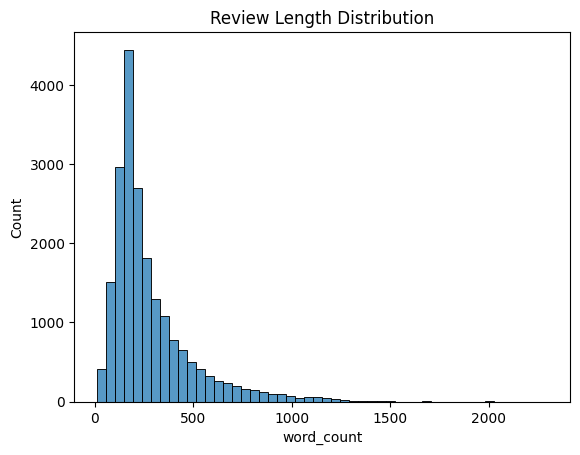

In [10]:
sns.histplot(df['word_count'], bins=50)
plt.title("Review Length Distribution")
plt.show()

* The above graph shown us Most movie reviews are short to medium,very few reviews are extremely long.
* Some reviews go till 1500–3000 words But count is very small-These are outliers.

### Step :8 Truncation
To limit the maximum sequence length, ensuring efficient model training while retaining most of the semantic information.

In [11]:
MAX_LEN = 400

df['truncated_review'] = df['review'].apply(
    lambda x: " ".join(x.split()[:MAX_LEN])
)

### Step 9: Sample Text Check

In [12]:
for i in range(2):
    print("Sentiment:", df.iloc[i]['sentiment'])
    print(df.iloc[i]['review'][:300])
    print("-"*80)

Sentiment: positive
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Tru
--------------------------------------------------------------------------------
Sentiment: positive
A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" 
--------------------------------------------------------------------------------


In [13]:
df.head()

,review,sentiment,labels,word_count,truncated_review
0,One of the other reviewers has mentioned that ...,positive,0,380,One of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,positive,0,201,A wonderful little production. <br /><br />The...
2,I thought this was a wonderful way to spend ti...,positive,0,205,I thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,negative,1,175,Basically there's a family where a little boy ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,0,283,"Petter Mattei's ""Love in the Time of Money"" is..."


#### Step 10:Select input and labels & Train–Validation Split

In [14]:
texts = df['truncated_review'].tolist()
labels = df['labels'].tolist()

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    texts,
    labels,
    test_size=0.2,
    random_state=42,         #Reproducibility
    stratify=labels           #Keeps label balance
)

##  Handover Note

This notebook completes:
- Exploratory Data Analysis (EDA)
- Label distribution analysis
- Review length analysis and outlier detection
- Truncation strategy justification
- Train–test data split
- Tokenization-ready preprocessing

The outputs from this notebook (train/validation datasets and preprocessing logic)
will be used by subsequent notebooks for transformer model fine-tuning
(BERT, RoBERTa, GPT-2).


# **Step 11: Implement and fine-tune BERT, RoBERTa, GPT‑2**

In [16]:
!pip install -q transformers datasets accelerate torch

import numpy as np
from datasets import Dataset, DatasetDict
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer
)
import torch

In [17]:
train_df = pd.DataFrame({"text": X_train, "label": y_train})
test_df  = pd.DataFrame({"text": X_test,  "label": y_test})

train_dataset = Dataset.from_pandas(train_df)
test_dataset  = Dataset.from_pandas(test_df)
dataset_dict = DatasetDict({"train": train_dataset, "test": test_dataset})

In [18]:
def finetune(model_name, is_gpt2=False, num_epochs=1):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    def tokenize_function(examples):
        return tokenizer(
            examples["text"],
            truncation=True,
            padding="max_length",
            max_length=256,
        )

    tokenized = dataset_dict.map(tokenize_function, batched=True)

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=2,
        ignore_mismatched_sizes=True,
    )
    if is_gpt2:
        model.config.pad_token_id = tokenizer.pad_token_id

    training_args = TrainingArguments(
        output_dir=f"./results-{model_name}",
        num_train_epochs=num_epochs,
        per_device_train_batch_size=8,
        gradient_accumulation_steps=2,
        learning_rate=2e-5,
        weight_decay=0.01,
        warmup_steps=500,
        logging_steps=50,
        fp16=torch.cuda.is_available(),
        save_strategy="no",
        eval_strategy="no",
        report_to="none",
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=tokenized["train"],
    )

    trainer.train()
    return trainer, model

print("Fine-tuning BERT (bert-base-uncased)...")
bert_trainer, bert_model = finetune("bert-base-uncased", is_gpt2=False, num_epochs=1)

print("Fine-tuning RoBERTa (roberta-base)...")
roberta_trainer, roberta_model = finetune("roberta-base", is_gpt2=False, num_epochs=1)

print("Fine-tuning GPT-2 (gpt2)...")
gpt2_trainer, gpt2_model = finetune("gpt2", is_gpt2=True, num_epochs=1)

print("Fine-tuning finished!")

Fine-tuning BERT (bert-base-uncased)...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

...

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key                  | Status     | 
---------------------+------------+-
h.{0...11}.attn.bias | UNEXPECTED | 
score.weight         | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,1.644643
100,1.475143
150,1.393835
200,1.302309
250,0.991992
300,0.776339
350,0.650135
400,0.633165
450,0.553638
500,0.533768


Fine-tuning finished!
